In [1]:
import numpy as np

### Generating data 'X' ranges between -10 to 10
### 'Y' is a linear combination of parameters as Y = ax+b+gaussian(0,epsilon)

In [2]:
Number_of_points = 1000
X_data = np.linspace(-10,10,Number_of_points)
W0_true = 11
W1_true = 4.5
Y_data = W1_true*X_data + W0_true + np.random.normal(0,0.5,Number_of_points)

### Split the data into training and testing set

In [3]:
Number_of_training = int(Number_of_points*0.8)
Number_of_testing = int(Number_of_points*0.2)
index = np.random.permutation(Number_of_points)
#index = np.random.permutation(10)
#print(index)
#print(index[:4])
#A random permutation of 1..N is generated

In [4]:
X_train = X_data[index[:Number_of_training]]
Y_train = Y_data[index[:Number_of_training]]

In [5]:
X_test = X_data[index[Number_of_training:]]
Y_test = Y_data[index[Number_of_training:]]

### Plot the data points

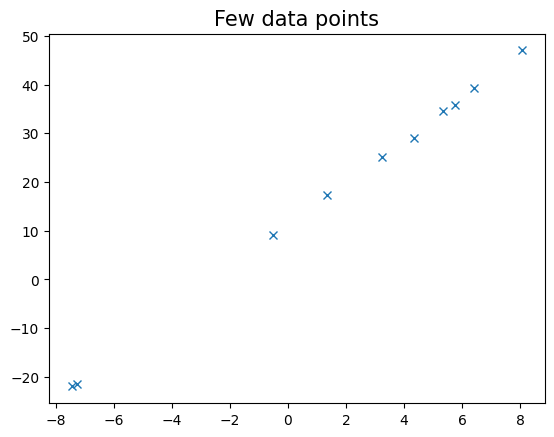

In [6]:
import matplotlib.pyplot as plt
def plot(x,y,title):
    fig,(ax1) = plt.subplots(1)
    if title!='Loss':
        ax1.plot(x,y,'x')
    else:
        ax1.plot(x,y)

    ax1.set_title(title, fontdict={'fontsize': 15, 'fontweight': 'medium'})
def plot_curve(x,y,W0,W1,title):
    fig,(ax1) = plt.subplots(1)
    #ax1.plot(x,y,'x')
    ax1.set_title(title, fontdict={'fontsize': 15, 'fontweight': 'medium'})
    y = W0 + W1*x
    #ax1.plot(x,y,'o')
    ax1.plot([X_data[0],X_data[-1]],[W0_true+W1_true*X_data[0],W0_true+W1_true*X_data[-1]],color = 'blue')
    ax1.plot([X_data[0],X_data[-1]],[W0+W1*X_data[0],W0+W1*X_data[-1]],color = 'red')


plot(X_train[0:10],Y_train[0:10],'Few data points')

### Fitting a 1st order polynomial  of type y = W0 + W1*x.
We want to learn the parameters W0 and W1. Lets initialize W0 and W1 with random values

In [7]:

def compute_loss(x,y,W0,W1):
    return np.sum(np.power(W0+W1*x - y,2))/(2.0*Number_of_training)


### Learning the parameters of the model for some 'N' epochs, by minimizing squared-difference error
$L(W) = \frac{1}{2}\Sigma_{n=1}^{N}(W^Tx_i - y_i)^2$

Epoch : 0\1000 Train loss: 318.94154770247843
Epoch : 50\1000 Train loss: 51.98748333329455
Epoch : 100\1000 Train loss: 42.394586583769176
Epoch : 150\1000 Train loss: 34.73295908875378
Epoch : 200\1000 Train loss: 28.460798632857063
Epoch : 250\1000 Train loss: 23.325975832859434
Epoch : 300\1000 Train loss: 19.122255886380884
Epoch : 350\1000 Train loss: 15.680800927301812
Epoch : 400\1000 Train loss: 12.863388638623558
Epoch : 450\1000 Train loss: 10.556860702392978
Epoch : 500\1000 Train loss: 8.66857791822584
Epoch : 550\1000 Train loss: 7.12269944999922
Epoch : 600\1000 Train loss: 5.857136760679516
Epoch : 650\1000 Train loss: 4.8210598933721505
Epoch : 700\1000 Train loss: 3.9728559410681665
Epoch : 750\1000 Train loss: 3.2784577092324865
Epoch : 800\1000 Train loss: 2.709975443774107
Epoch : 850\1000 Train loss: 2.244576669231727
Epoch : 900\1000 Train loss: 1.8635691470869933
Epoch : 950\1000 Train loss: 1.5516501222171504


C:\Users\anubh\AppData\Local\Temp\ipykernel_11508\516755907.py:3: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig,(ax1) = plt.subplots(1)


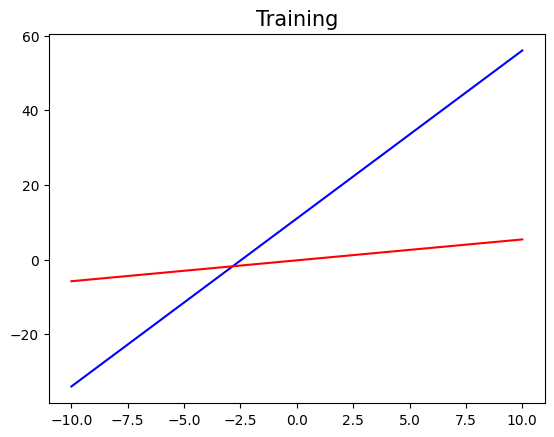

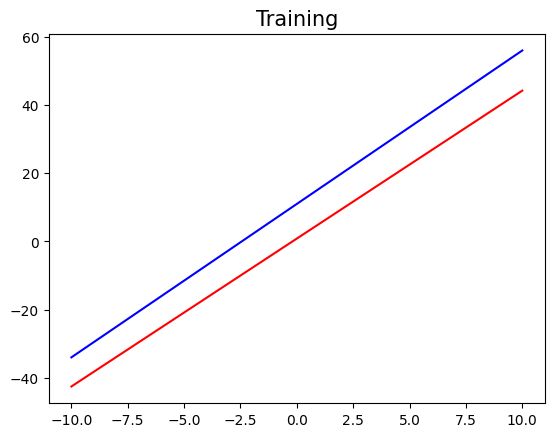

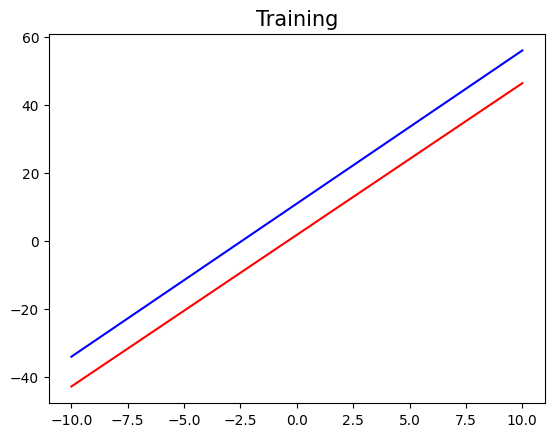

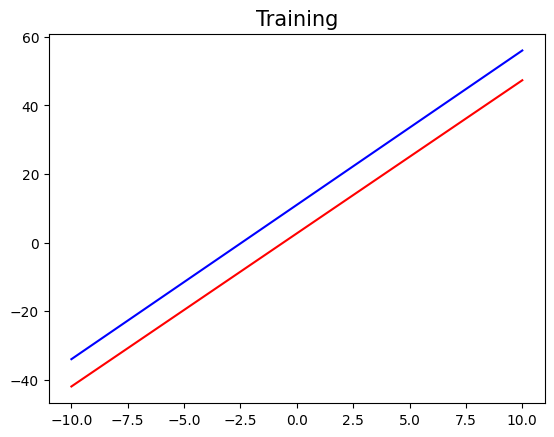

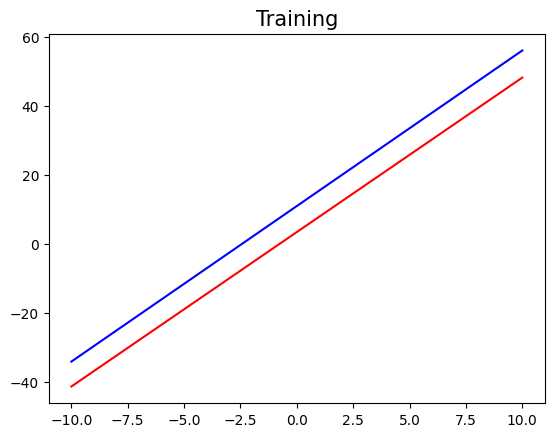

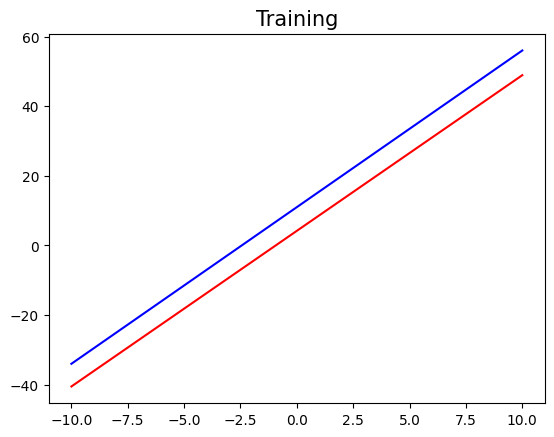

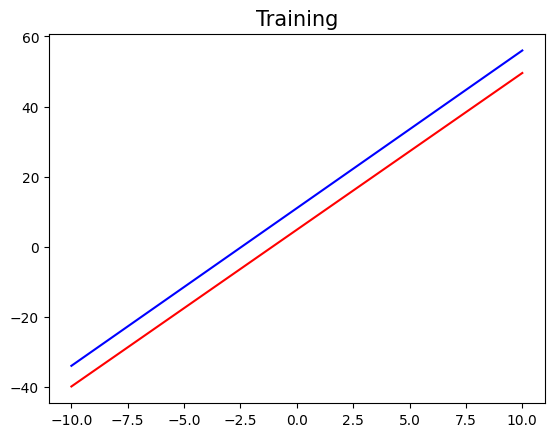

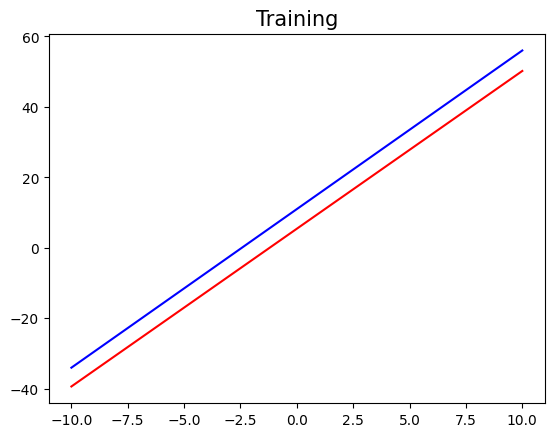

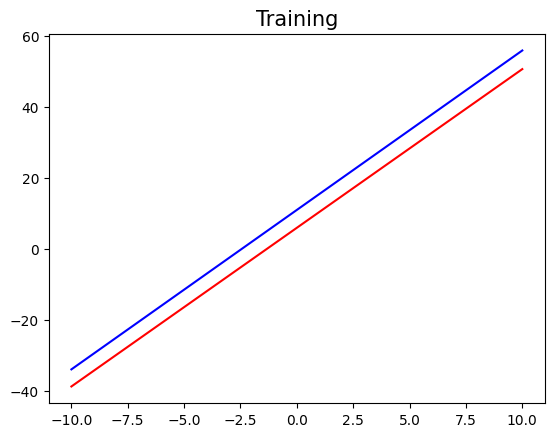

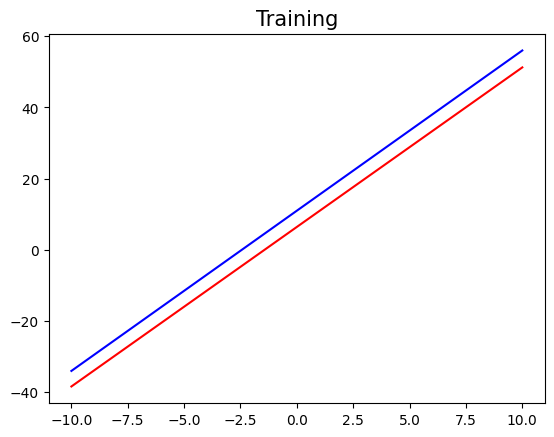

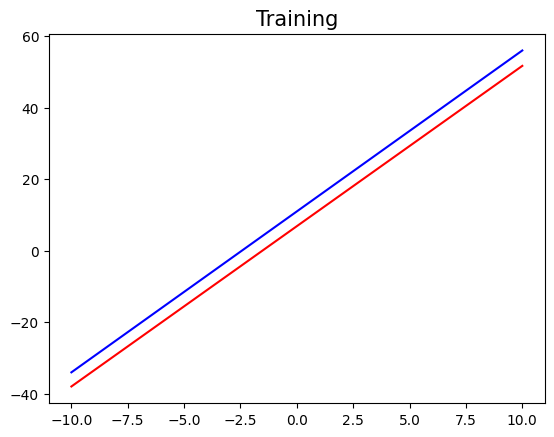

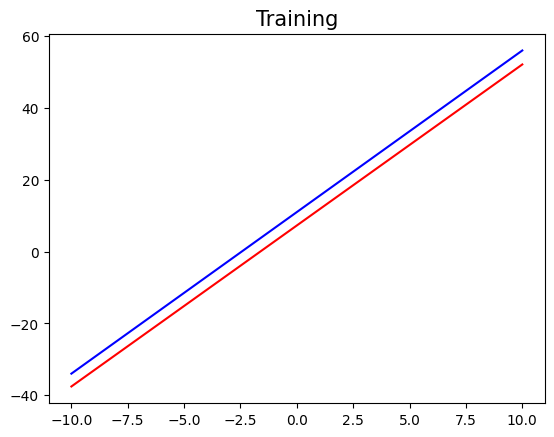

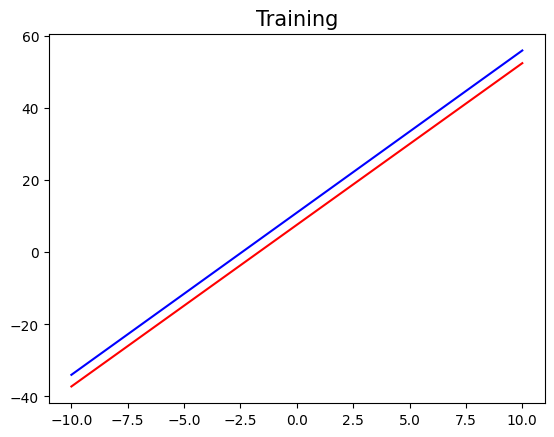

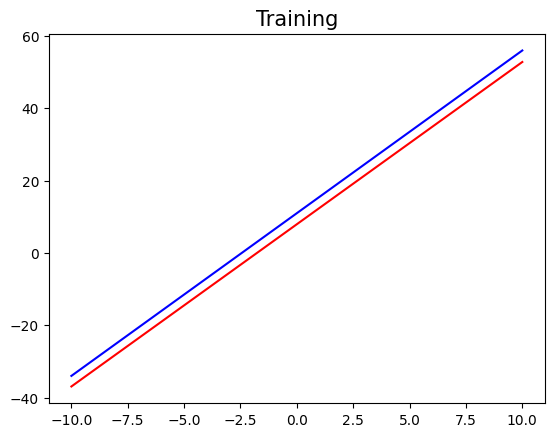

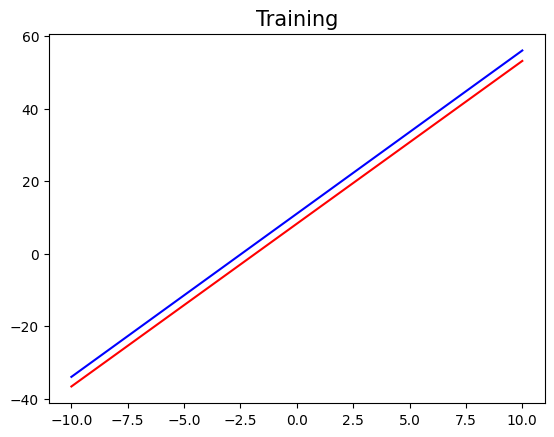

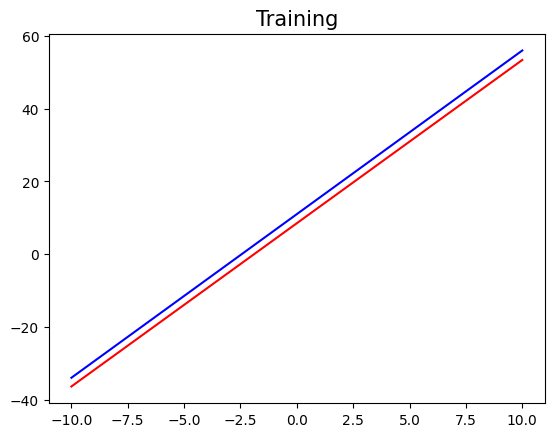

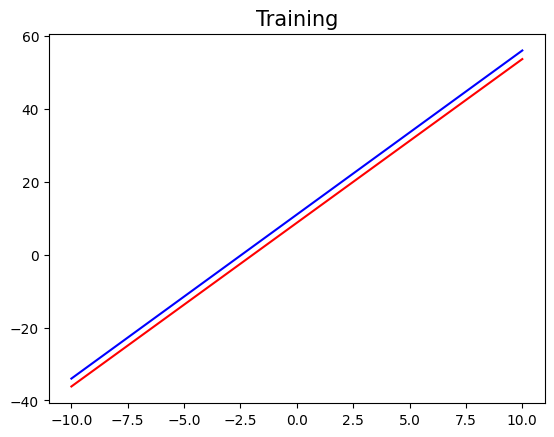

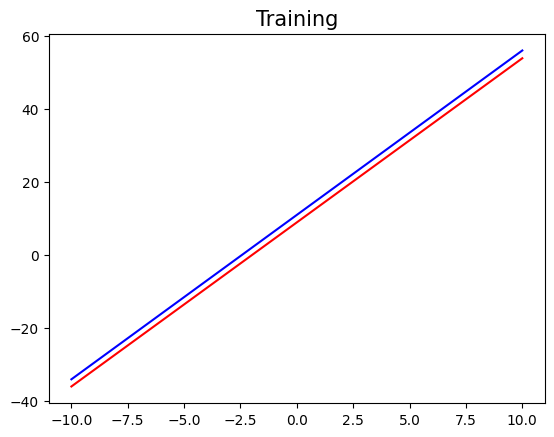

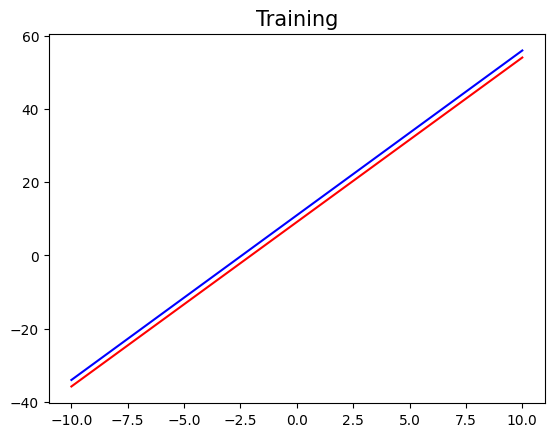

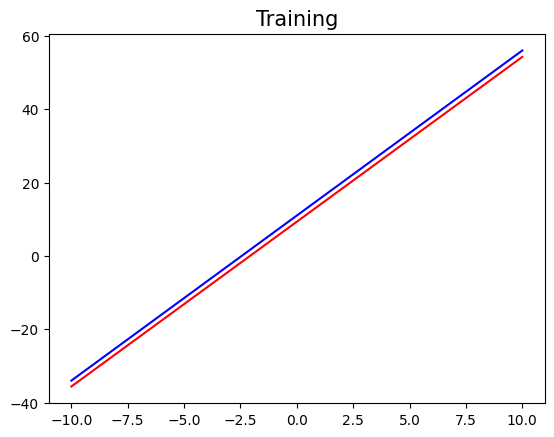

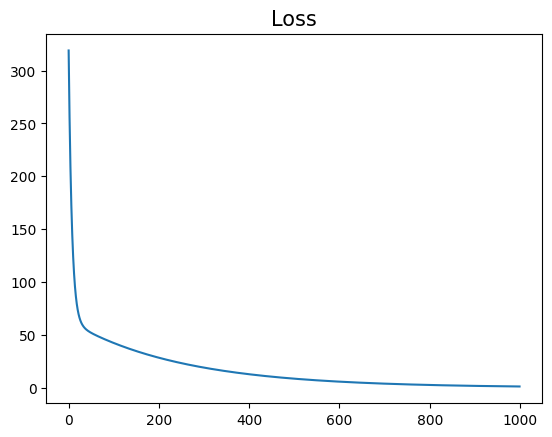

In [8]:
Epochs = 1000
learning_rate = 0.002
W0 = np.random.normal(0,0.2,1)
W1 = np.random.normal(0,0.2,1)
Loss = []
for epoch in range(Epochs):
    dW0 = 0;dW1 = 0
    for n in range(Number_of_training):
        dW0 = dW0 + (W0 + W1*X_train[n] - Y_train[n])*1
        dW1 = dW1 + (W0 + W1*X_train[n] - Y_train[n])*X_train[n]
    W0 = W0 - learning_rate*dW0/Number_of_training
    W1 = W1 - learning_rate*dW1/Number_of_training
    Loss.append(compute_loss(X_train,Y_train,W0,W1))
    if epoch%50==0:
        plot_curve(X_train,Y_train,W0,W1,'Training')
        print("Epoch : "+str(epoch)+"\\"+str(Epochs) + " Train loss: "+str(compute_loss(X_train,Y_train,W0,W1)))
            #plot_curve(X_train,Y_train,W,'Training')


plot(range(len(Loss)),Loss,'Loss')




